In [1]:
import numpy as np
import pandas as pd
import torch

from medmnist import ChestMNIST, INFO
from torchvision import transforms
from torchvision.models import resnet18
from sklearn.metrics import roc_auc_score, average_precision_score

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

train_data = ChestMNIST(
    split="train",
    transform=transform,
    download=True
)

test_data = ChestMNIST(
    split="test",
    transform=transform,
    download=True
)

class_names = list(INFO["chestmnist"]["label"].values())

print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Diseases:", len(class_names))

Training images: 78468
Test images: 22433
Diseases: 14


In [3]:
import torch.nn as nn

def create_resnet():
    model = resnet18(weights=None)

    model.conv1 = nn.Conv2d(
        1, 64, kernel_size=7,
        stride=2, padding=3, bias=False
    )

    model.fc = nn.Linear(model.fc.in_features, 14)

    return model

In [4]:
model = create_resnet().to(device)

model.load_state_dict(
    torch.load(
        "resnet18_chestMNIST.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Original ResNet-18 loaded successfully!")

Original ResNet-18 loaded successfully!


In [5]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

all_probs = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.numpy())

all_probs = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

print("Predictions:", all_probs.shape)
print("Labels:", all_labels.shape)

Predictions: (22433, 14)
Labels: (22433, 14)


In [6]:
results = []

train_labels = train_data.labels

for i, disease in enumerate(class_names):
    prevalence = train_labels[:, i].mean()

    auroc = roc_auc_score(
        all_labels[:, i],
        all_probs[:, i]
    )

    pr_auc = average_precision_score(
        all_labels[:, i],
        all_probs[:, i]
    )

    results.append({
        "Disease": disease,
        "Positive Samples": int(train_labels[:, i].sum()),
        "Prevalence (%)": prevalence * 100,
        "AUROC": auroc,
        "PR-AUC": pr_auc
    })

df = pd.DataFrame(results)

display(df.sort_values("Prevalence (%)"))

,Disease,Positive Samples,Prevalence (%),AUROC,PR-AUC
13,hernia,144,0.183514,0.785879,0.006694
6,pneumonia,978,1.246368,0.677612,0.021823
11,fibrosis,1158,1.475761,0.715686,0.040969
9,edema,1690,2.153744,0.858054,0.112019
10,emphysema,1799,2.292654,0.737924,0.070747
1,cardiomegaly,1950,2.485089,0.852819,0.198303
12,pleural,2279,2.904369,0.706164,0.085033
8,consolidation,3263,4.158383,0.763708,0.118455
7,pneumothorax,3705,4.721670,0.771972,0.158848
4,mass,3988,5.082327,0.696334,0.133780


In [7]:
print("Prevalence vs AUROC:")
print(df["Prevalence (%)"].corr(df["AUROC"]))

print("\nPrevalence vs PR-AUC:")
print(df["Prevalence (%)"].corr(df["PR-AUC"]))

Prevalence vs AUROC:
-0.2276705897896279

Prevalence vs PR-AUC:
0.8532955712023446


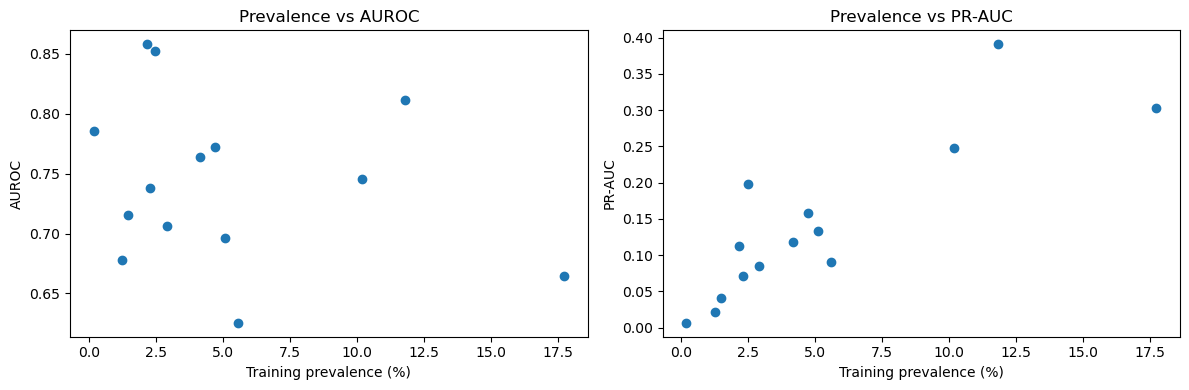

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df["Prevalence (%)"], df["AUROC"])
axes[0].set_xlabel("Training prevalence (%)")
axes[0].set_ylabel("AUROC")
axes[0].set_title("Prevalence vs AUROC")

axes[1].scatter(df["Prevalence (%)"], df["PR-AUC"])
axes[1].set_xlabel("Training prevalence (%)")
axes[1].set_ylabel("PR-AUC")
axes[1].set_title("Prevalence vs PR-AUC")

plt.tight_layout()
plt.show()